<a href="https://colab.research.google.com/github/RehanAfzalkhan/Fraud-Detection/blob/main/Fraud_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Classification with Imbalanced Data
**Muhammad Rehan Afzal

This notebook compares Logistic Regression, Logistic Regression with SMOTE, and Random Forest on credit card fraud detection.

**Run instructions:** In Google Colab, select **Runtime > Run all**. The dataset downloads automatically through KaggleHub. No manual CSV upload is required; internet access is needed.

**Notebook order:** Setup → Part 1: exploration → Part 2: preprocessing and baseline → Part 3: SMOTE → Part 4: ensemble → Part 5: final evaluation and discussion.

Fraud is the positive class (`Class = 1`); non-fraud is `Class = 0`. Precision, recall, and F1 refer to fraud throughout. Original-data exploration and cleaned-data modeling are reported separately.


## Setup
### Step 0.1 — Install and import libraries

Import the libraries used for downloading, analysis, and plotting.

In [18]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from google.colab import files
%pip install -q kagglehub

import kagglehub
import pandas as pd
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 35)
plt.rcParams["figure.figsize"] = (9, 5)
print("Libraries imported.")

Libraries imported.


**Result:** The required libraries are loaded. Run the following cells in order.

## Part 1 — Introduction to imbalanced data
### Step 1.1 — Download and load the dataset

Download the Credit Card Fraud Detection dataset using KaggleHub and validate its columns and target labels.

In [19]:
# Download latest version using KaggleHub.
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
print("Path to dataset files:", path)

csv_files = list(Path(path).rglob("creditcard.csv"))
if len(csv_files) != 1:
    raise FileNotFoundError(f"Expected one creditcard.csv in {path}; found {len(csv_files)}.")
filename = csv_files[0]
df = pd.read_csv(filename)
expected_columns = {"Time", "Amount", "Class"} | {f"V{i}" for i in range(1, 29)}
missing_columns = expected_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"Expected credit card dataset columns missing: {sorted(missing_columns)}")
if df.empty or df["Class"].isna().any() or not set(df["Class"].unique()).issubset({0, 1}):
    raise ValueError("The dataset must contain rows with valid Class labels 0 and 1.")
if df["Class"].nunique() != 2:
    raise ValueError("Both non-fraud (0) and fraud (1) transactions are required.")
print(f"Loaded: {filename.name}")
display(df.head())

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Path to dataset files: /kaggle/input/creditcardfraud
Loaded: creditcard.csv


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


**Result:** The dataset loaded successfully. The displayed rows show the 30 input features and the target column.

### Step 1.2 — Inspect dataset size and features

Report sample count, feature count, data types, and memory use.

In [20]:
feature_columns = df.columns.drop("Class").tolist()
n_samples = len(df)
n_features = len(feature_columns)
print(f"Samples (transactions): {n_samples:,}")
print(f"Input features (excluding Class): {n_features}")
print(f"Total columns (including Class): {df.shape[1]}")
print(f"Memory usage: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
print("\nFeature names:", feature_columns)
print("\nColumn information:")
df.info()

Samples (transactions): 284,807
Input features (excluding Class): 30
Total columns (including Class): 31
Memory usage: 67.36 MB

Feature names: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-

**Result:** There are 284,807 transactions and 30 input features, plus the Class target.

### Step 1.3 — Check missing values and duplicates

Check missing values, infinite numeric values, and exact duplicate rows without modifying the original dataframe.

In [21]:
quality = pd.DataFrame({
    "Data type": df.dtypes.astype(str),
    "Missing values": df.isna().sum(),
    "Missing (%)": df.isna().mean() * 100,
})
display(quality)
numeric_df = df.select_dtypes(include=np.number)
infinite_count = int(np.isinf(numeric_df.to_numpy()).sum())
duplicate_count = int(df.duplicated().sum())
print(f"Total missing values: {df.isna().sum().sum():,}")
print(f"Infinite numeric values: {infinite_count:,}")
print(f"Duplicate rows beyond first occurrence: {duplicate_count:,}")
print("No rows have been removed.")

,Data type,Missing values,Missing (%)
Time,float64,0,0.0
V1,float64,0,0.0
V2,float64,0,0.0
V3,float64,0,0.0
V4,float64,0,0.0
V5,float64,0,0.0
V6,float64,0,0.0
V7,float64,0,0.0
V8,float64,0,0.0
V9,float64,0,0.0


Total missing values: 0
Infinite numeric values: 0
Duplicate rows beyond first occurrence: 1,081
No rows have been removed.


**Result:** No missing or infinite values were found. There are 1,081 duplicate rows beyond their first occurrences; these are removed before modeling.

### Step 1.4 — Summarize feature and transaction amounts

Calculate descriptive statistics and compare transaction amounts by class.

In [22]:
display(df[feature_columns].describe().T)
print("Transaction amount by class:")
display(df.groupby("Class")["Amount"].describe().rename(index={0: "Non-fraud", 1: "Fraud"}))

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.168375e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.416908e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.074095e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,9.604066e-16,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.487313e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.556467e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.213481e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.406331e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


Transaction amount by class:


,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
Non-fraud,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
Fraud,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


**Result:** The amount mean exceeds its median in both classes, indicating right-skewed distributions. Amount alone does not separate all fraud from non-fraud.

### Step 1.5 — Calculate class counts and percentages

Calculate the majority and minority class proportions and their imbalance ratio.

In [23]:
class_counts = df["Class"].value_counts().reindex([0, 1], fill_value=0)
class_percentages = class_counts / n_samples * 100
class_summary = pd.DataFrame({
    "Class": [0, 1],
    "Label": ["Non-fraud", "Fraud"],
    "Samples": class_counts.to_numpy(),
    "Percentage (%)": class_percentages.to_numpy(),
})
display(class_summary.style.format({"Samples": "{:,.0f}", "Percentage (%)": "{:.4f}"}))
majority_label = class_counts.idxmax()
minority_label = class_counts.idxmin()
imbalance_ratio = class_counts.max() / class_counts.min()
print(f"Majority class: {majority_label}; minority class: {minority_label}")
print(f"Majority-to-minority ratio: {imbalance_ratio:,.2f}:1")

,Class,Label,Samples,Percentage (%)
0,0,Non-fraud,"284,315",99.8273
1,1,Fraud,492,0.1727


Majority class: 0; minority class: 1
Majority-to-minority ratio: 577.88:1


**Result:** The original data contain 492 fraud cases (0.1727%) and 284,315 non-fraud cases (99.8273%), approximately 578 non-fraud transactions per fraud case.

### Step 1.6 — Plot class imbalance

Plot class percentages and counts. The count plot uses a log scale so the small fraud class remains visible.

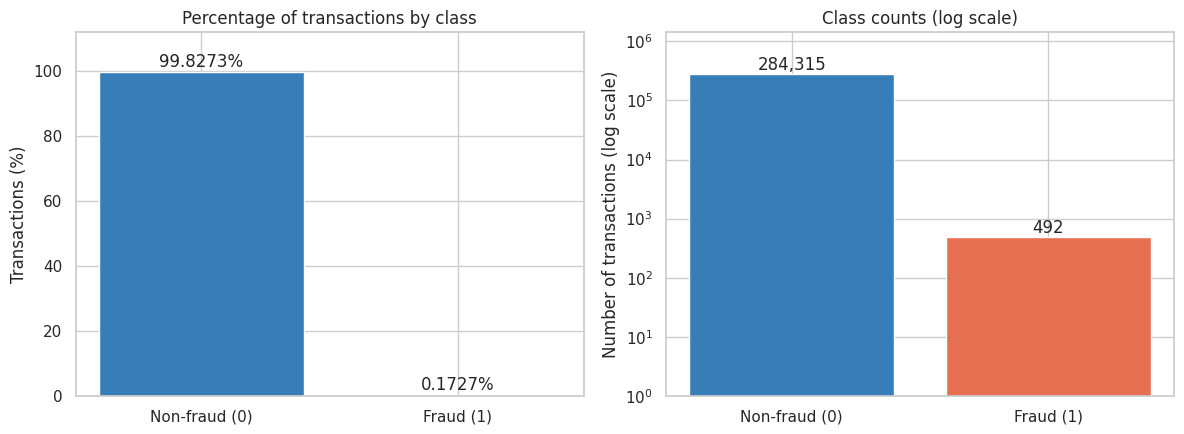

In [24]:
labels = ["Non-fraud (0)", "Fraud (1)"]
colors = ["#377eb8", "#e76f51"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
bars = axes[0].bar(labels, class_percentages.to_numpy(), color=colors)
axes[0].set_title("Percentage of transactions by class")
axes[0].set_ylabel("Transactions (%)")
axes[0].set_ylim(0, 112)
for bar, value in zip(bars, class_percentages):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5,
                 f"{value:.4f}%", ha="center")
bars = axes[1].bar(labels, class_counts.to_numpy(), color=colors)
axes[1].set_yscale("log")
axes[1].set_ylim(1, class_counts.max() * 5)
axes[1].set_title("Class counts (log scale)")
axes[1].set_ylabel("Number of transactions (log scale)")
for bar, value in zip(bars, class_counts):
    axes[1].text(bar.get_x() + bar.get_width()/2, value * 1.15,
                 f"{value:,}", ha="center")
plt.tight_layout()
plt.show()

**Result:** The plots show severe class imbalance: fraud makes up less than 0.2% of the original data.

### Step 1.7 — Explore amount and time distributions

Compare log-transformed transaction amounts and elapsed transaction times by class. These plots do not change the dataframe.

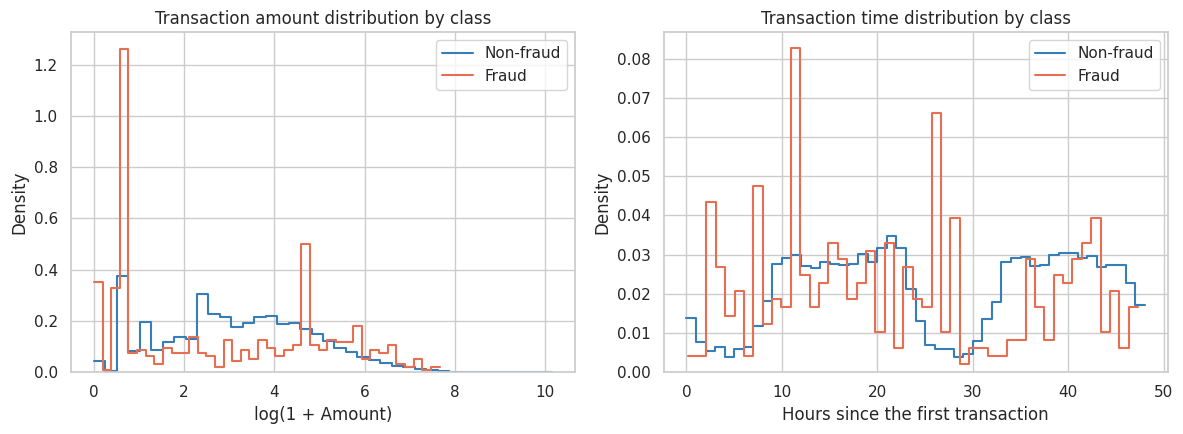

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for label, name, color in zip([0, 1], ["Non-fraud", "Fraud"], colors):
    subset = df.loc[df["Class"] == label]
    sns.histplot(np.log1p(subset["Amount"].dropna()), bins=40, stat="density",
                 element="step", fill=False, color=color, label=name, ax=axes[0])
    sns.histplot(subset["Time"].dropna() / 3600, bins=48, stat="density",
                 element="step", fill=False, color=color, label=name, ax=axes[1])
axes[0].set_title("Transaction amount distribution by class")
axes[0].set_xlabel("log(1 + Amount)")
axes[1].set_title("Transaction time distribution by class")
axes[1].set_xlabel("Hours since the first transaction")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

**Result:** The density plots compare distribution shapes rather than class counts. The original Time and Amount features remain unchanged.

### Step 1.8 — Summarize the original dataset

Print the main exploration findings and the accuracy of always predicting non-fraud.

In [26]:
fraud_count = int(class_counts.loc[1])
nonfraud_count = int(class_counts.loc[0])
print(f"The uploaded dataset contains {n_samples:,} transactions and {n_features} input features.")
print(f"Non-fraud transactions: {nonfraud_count:,} ({class_percentages.loc[0]:.4f}%).")
print(f"Fraud transactions: {fraud_count:,} ({class_percentages.loc[1]:.4f}%).")
print(f"Missing values: {df.isna().sum().sum():,}; infinite values: {infinite_count:,}; duplicate rows: {duplicate_count:,}.")
print(f"Predicting every transaction as non-fraud would give {class_percentages.loc[0]:.4f}% accuracy,")
print("but would detect none of the fraud cases (fraud recall = 0%).")
print("Therefore, later model evaluation should include fraud precision, recall, F1-score, and the confusion matrix.")

The uploaded dataset contains 284,807 transactions and 30 input features.
Non-fraud transactions: 284,315 (99.8273%).
Fraud transactions: 492 (0.1727%).
Missing values: 0; infinite values: 0; duplicate rows: 1,081.
Predicting every transaction as non-fraud would give 99.8273% accuracy,
but would detect none of the fraud cases (fraud recall = 0%).
Therefore, later model evaluation should include fraud precision, recall, F1-score, and the confusion matrix.


**Result:** Always predicting non-fraud gives 99.8273% accuracy but zero fraud recall. Accuracy alone is therefore insufficient.

## Part 2 — Preprocessing and baseline classifier
### Step 2.1 — Remove exact duplicates

Create a separate cleaned dataframe before splitting to avoid identical records occurring in different subsets. Retain the original dataframe for Part 1.

In [27]:
# Remove exact duplicates for model training
df_clean = df.drop_duplicates().reset_index(drop=True)

print(f"Original rows: {len(df):,}")
print(f"Duplicates removed: {len(df) - len(df_clean):,}")
print(f"Remaining rows: {len(df_clean):,}")
print(f"Remaining duplicates: {df_clean.duplicated().sum()}")

print("\nClass counts (0 = non-fraud, 1 = fraud):")
print(df_clean["Class"].value_counts().sort_index())

Original rows: 284,807
Duplicates removed: 1,081
Remaining rows: 283,726
Remaining duplicates: 0

Class counts (0 = non-fraud, 1 = fraud):
Class
0    283253
1       473
Name: count, dtype: int64


**Result:** Removing 1,081 duplicates leaves 283,726 transactions: 283,253 non-fraud and 473 fraud. No exact duplicates remain.

### Step 2.2 — Create stratified train, validation, and test splits

Separate features from the target and use a 70/15/15 split with random_state=42. Stratification approximately preserves the fraud proportion.

In [28]:
from sklearn.model_selection import train_test_split

# Separate input features and target
X = df_clean.drop(columns="Class")
y = df_clean["Class"]

# 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

# Divide the remaining 30% into 15% validation and 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

# Display sample counts and class distributions
split_summary = pd.DataFrame([
    {
        "Split": name,
        "Samples": len(labels),
        "Percentage (%)": 100 * len(labels) / len(df_clean),
        "Non-fraud": int((labels == 0).sum()),
        "Fraud": int((labels == 1).sum()),
        "Fraud (%)": 100 * (labels == 1).mean()
    }
    for name, labels in [
        ("Training", y_train),
        ("Validation", y_val),
        ("Testing", y_test)
    ]
])

display(split_summary.round(4))

# Verify that the splits do not overlap
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_val) + len(X_test) == len(df_clean)

print("Data split successfully. No overlap between subsets.")

,Split,Samples,Percentage (%),Non-fraud,Fraud,Fraud (%)
0,Training,198608,69.9999,198277,331,0.1667
1,Validation,42559,15.0000,42488,71,0.1668
2,Testing,42559,15.0000,42488,71,0.1668


Data split successfully. No overlap between subsets.


**Result:** Training contains 198,608 transactions (331 fraud); validation and testing each contain 42,559 (71 fraud). The index checks confirm no overlap.

### Step 2.3 — Scale features using training data only

Fit StandardScaler only on training data and transform validation and test features with the fitted scaler. Use scaled inputs for Logistic Regression and SMOTE.

In [29]:
from sklearn.preprocessing import StandardScaler

# Learn scaling parameters from training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Features scaled successfully.")
print("Training:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Testing:", X_test_scaled.shape)

Features scaled successfully.
Training: (198608, 30)
Validation: (42559, 30)
Testing: (42559, 30)


**Result:** All subsets retain 30 features. Scaling uses no validation or test statistics and leaves class counts unchanged.

### Step 2.4 — Train and validate baseline Logistic Regression

I selected Logistic Regression because this is binary classification and it provides a simple, interpretable baseline. Train with C=1.0 and max_iter=2000, without resampling or class weighting; report validation metrics and a confusion matrix.

Baseline Logistic Regression — Validation Results


,Accuracy,Precision,Recall,F1-score
0,0.999,0.8333,0.493,0.6195


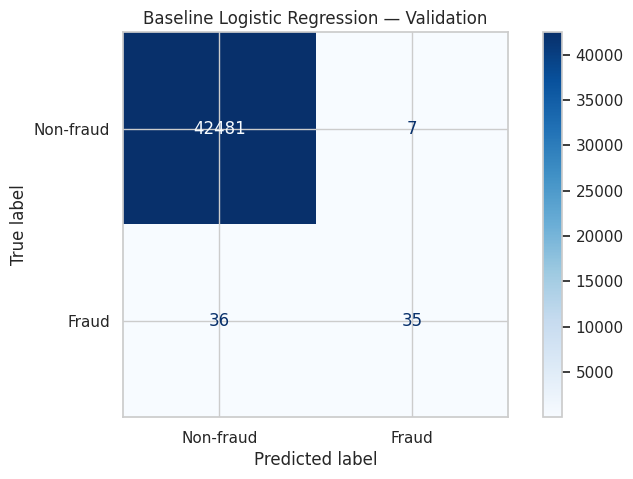

TN: 42481 | FP: 7 | FN: 36 | TP: 35


In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay
)

# Train on the original imbalanced training split
lr_baseline = LogisticRegression(
    C=1.0,
    max_iter=2000,
    class_weight=None,
    random_state=42
)

lr_baseline.fit(X_train_scaled, y_train)

# Evaluate on validation data
y_val_pred_lr = lr_baseline.predict(X_val_scaled)

baseline_val_metrics = {
    "Accuracy": accuracy_score(y_val, y_val_pred_lr),
    "Precision": precision_score(
        y_val, y_val_pred_lr, pos_label=1, zero_division=0
    ),
    "Recall": recall_score(
        y_val, y_val_pred_lr, pos_label=1, zero_division=0
    ),
    "F1-score": f1_score(
        y_val, y_val_pred_lr, pos_label=1, zero_division=0
    )
}

print("Baseline Logistic Regression — Validation Results")
display(pd.DataFrame([baseline_val_metrics]).round(4))

# Confusion matrix: rows = actual, columns = predicted
cm_lr_val = confusion_matrix(y_val, y_val_pred_lr, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm_lr_val,
    display_labels=["Non-fraud", "Fraud"]
).plot(cmap="Blues", values_format="d")

plt.title("Baseline Logistic Regression — Validation")
plt.show()

tn, fp, fn, tp = cm_lr_val.ravel()
print(f"TN: {tn} | FP: {fp} | FN: {fn} | TP: {tp}")

**Result:** On validation data, the baseline detects 35 of 71 fraud cases with 7 false alarms. Fraud recall is 49.30% and F1 is 61.95%, despite 99.90% accuracy.

## Part 3 — Resampling with SMOTE
### Step 3.1 — Balance training data, retrain, and validate

SMOTE interpolates between neighboring minority samples to generate synthetic fraud examples. Apply it only to scaled training data, then train Logistic Regression with the same settings as the baseline. Evaluate on unchanged validation data.

Training class counts BEFORE SMOTE:
Class
0    198277
1       331
Name: count, dtype: int64

Training class counts AFTER SMOTE:
Class
0    198277
1    198277
Name: count, dtype: int64

Logistic Regression + SMOTE — Validation Results


,Accuracy,Precision,Recall,F1-score
0,0.9709,0.0487,0.8873,0.0924


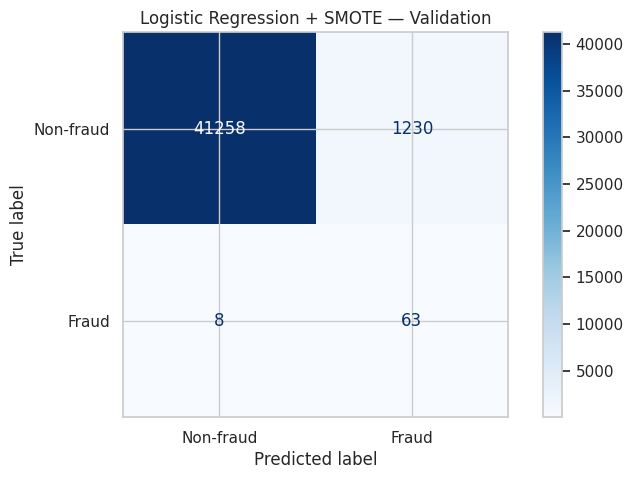

TN: 41258 | FP: 1230 | FN: 8 | TP: 63

Validation comparison:


,Accuracy,Precision,Recall,F1-score
Baseline Logistic Regression,0.9990,0.8333,0.4930,0.6195
Logistic Regression + SMOTE,0.9709,0.0487,0.8873,0.0924


In [31]:
%pip install -q imbalanced-learn

from imblearn.over_sampling import SMOTE

# Balance only the scaled training data
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled, y_train
)

print("Training class counts BEFORE SMOTE:")
print(y_train.value_counts().sort_index())

print("\nTraining class counts AFTER SMOTE:")
print(pd.Series(y_train_smote).value_counts().sort_index())

# Use the same settings as the baseline
lr_smote = LogisticRegression(
    C=1.0,
    max_iter=2000,
    class_weight=None,
    random_state=42
)

lr_smote.fit(X_train_smote, y_train_smote)

# Evaluate on the same unchanged validation set
y_val_pred_smote = lr_smote.predict(X_val_scaled)

smote_val_metrics = {
    "Accuracy": accuracy_score(y_val, y_val_pred_smote),
    "Precision": precision_score(
        y_val, y_val_pred_smote, pos_label=1, zero_division=0
    ),
    "Recall": recall_score(
        y_val, y_val_pred_smote, pos_label=1, zero_division=0
    ),
    "F1-score": f1_score(
        y_val, y_val_pred_smote, pos_label=1, zero_division=0
    )
}

print("\nLogistic Regression + SMOTE — Validation Results")
display(pd.DataFrame([smote_val_metrics]).round(4))

cm_smote_val = confusion_matrix(
    y_val, y_val_pred_smote, labels=[0, 1]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_smote_val,
    display_labels=["Non-fraud", "Fraud"]
).plot(cmap="Blues", values_format="d")

plt.title("Logistic Regression + SMOTE — Validation")
plt.show()

tn, fp, fn, tp = cm_smote_val.ravel()
print(f"TN: {tn} | FP: {fp} | FN: {fn} | TP: {tp}")

# Compare against the baseline
print("\nValidation comparison:")
display(pd.DataFrame(
    [baseline_val_metrics, smote_val_metrics],
    index=["Baseline Logistic Regression", "Logistic Regression + SMOTE"]
).round(4))

**Result:** SMOTE balances training to 198,277 examples per class. Validation recall rises to 88.73%, but 1,230 false alarms reduce precision to 4.87% and F1 to 9.24%.

## Part 4 — Ensemble classification
### Step 4.1 — Train and validate Random Forest

Random Forest combines decision trees built using bootstrap samples and random feature subsets to capture nonlinear relationships. Train 200 trees on the unscaled, imbalanced training split with random_state=42, without SMOTE or class weighting.

Random Forest — Validation Results


,Accuracy,Precision,Recall,F1-score
0,0.9996,0.9825,0.7887,0.875


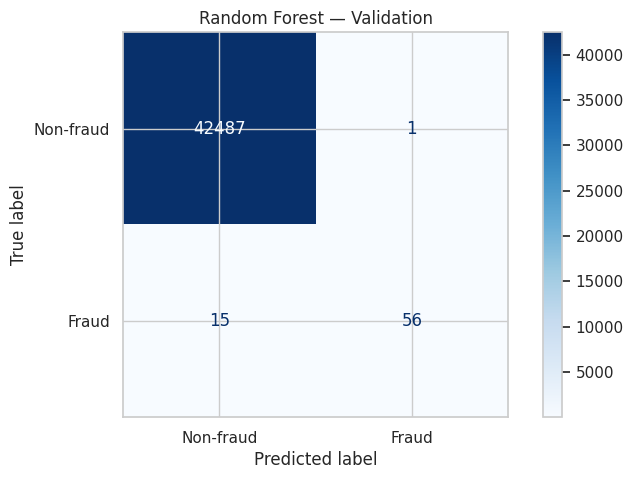

TN: 42487 | FP: 1 | FN: 15 | TP: 56

Validation comparison — all three models:


,Accuracy,Precision,Recall,F1-score
Baseline Logistic Regression,0.9990,0.8333,0.4930,0.6195
Logistic Regression + SMOTE,0.9709,0.0487,0.8873,0.0924
Random Forest,0.9996,0.9825,0.7887,0.8750


In [32]:
from sklearn.ensemble import RandomForestClassifier

# Train on the original imbalanced training split
rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight=None,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

# Evaluate on the same validation set
y_val_pred_rf = rf_model.predict(X_val)

rf_val_metrics = {
    "Accuracy": accuracy_score(y_val, y_val_pred_rf),
    "Precision": precision_score(
        y_val, y_val_pred_rf, pos_label=1, zero_division=0
    ),
    "Recall": recall_score(
        y_val, y_val_pred_rf, pos_label=1, zero_division=0
    ),
    "F1-score": f1_score(
        y_val, y_val_pred_rf, pos_label=1, zero_division=0
    )
}

print("Random Forest — Validation Results")
display(pd.DataFrame([rf_val_metrics]).round(4))

# Draw confusion matrix
cm_rf_val = confusion_matrix(
    y_val, y_val_pred_rf, labels=[0, 1]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_rf_val,
    display_labels=["Non-fraud", "Fraud"]
).plot(cmap="Blues", values_format="d")

plt.title("Random Forest — Validation")
plt.show()

tn, fp, fn, tp = cm_rf_val.ravel()
print(f"TN: {tn} | FP: {fp} | FN: {fn} | TP: {tp}")

# Compare all three models on validation data
validation_results = pd.DataFrame(
    [baseline_val_metrics, smote_val_metrics, rf_val_metrics],
    index=[
        "Baseline Logistic Regression",
        "Logistic Regression + SMOTE",
        "Random Forest"
    ]
)

print("\nValidation comparison — all three models:")
display(validation_results.round(4))

**Result:** Random Forest detects 56 of 71 validation fraud cases with 1 false alarm. Its precision is 98.25%, recall 78.87%, and F1 87.50%, the highest validation F1 among these models.

## Part 5 — Final comparison, analysis, and reflection
### Step 5.1 — Evaluate all three models on the test set

Keep the trained model settings fixed and evaluate all models on the same held-out test set. Plot confusion matrices and report accuracy, fraud precision, recall, F1, and TN/FP/FN/TP counts. Matrix rows are actual labels and columns are predicted labels.

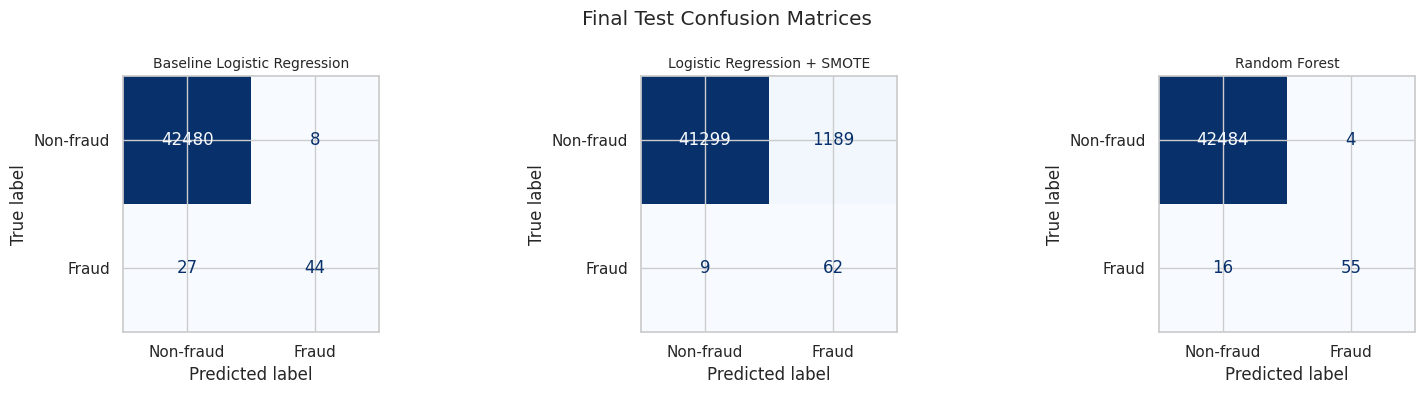

Final Test Results


,Accuracy,Precision,Recall,F1-score,TN,FP,FN,TP
Model,,,,,,,,
Baseline Logistic Regression,0.9992,0.8462,0.6197,0.7154,42480,8,27,44
Logistic Regression + SMOTE,0.9719,0.0496,0.8732,0.0938,41299,1189,9,62
Random Forest,0.9995,0.9322,0.7746,0.8462,42484,4,16,55


In [33]:
# Final test evaluation — keep model settings fixed
models_to_test = [
    ("Baseline Logistic Regression", lr_baseline, X_test_scaled),
    ("Logistic Regression + SMOTE", lr_smote, X_test_scaled),
    ("Random Forest", rf_model, X_test)
]

test_rows = []
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, model, features) in zip(axes, models_to_test):
    predictions = model.predict(features)

    cm = confusion_matrix(y_test, predictions, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    test_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp
    })

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Non-fraud", "Fraud"]
    ).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)

    ax.set_title(name, fontsize=10)

fig.suptitle("Final Test Confusion Matrices")
plt.tight_layout()
plt.show()

test_results = pd.DataFrame(test_rows).set_index("Model")

print("Final Test Results")
display(test_results.round(4))

**Result:** Random Forest has the highest test F1 (84.62%): 55 detected fraud, 16 missed fraud, and 4 false alarms. SMOTE has the highest recall (87.32%) but generates 1,189 false alarms. Baseline F1 is 71.54%.

### Step 5.2 — Plot the final test metrics

Compare test accuracy, precision, recall, and F1 across the three models using percentage scores.

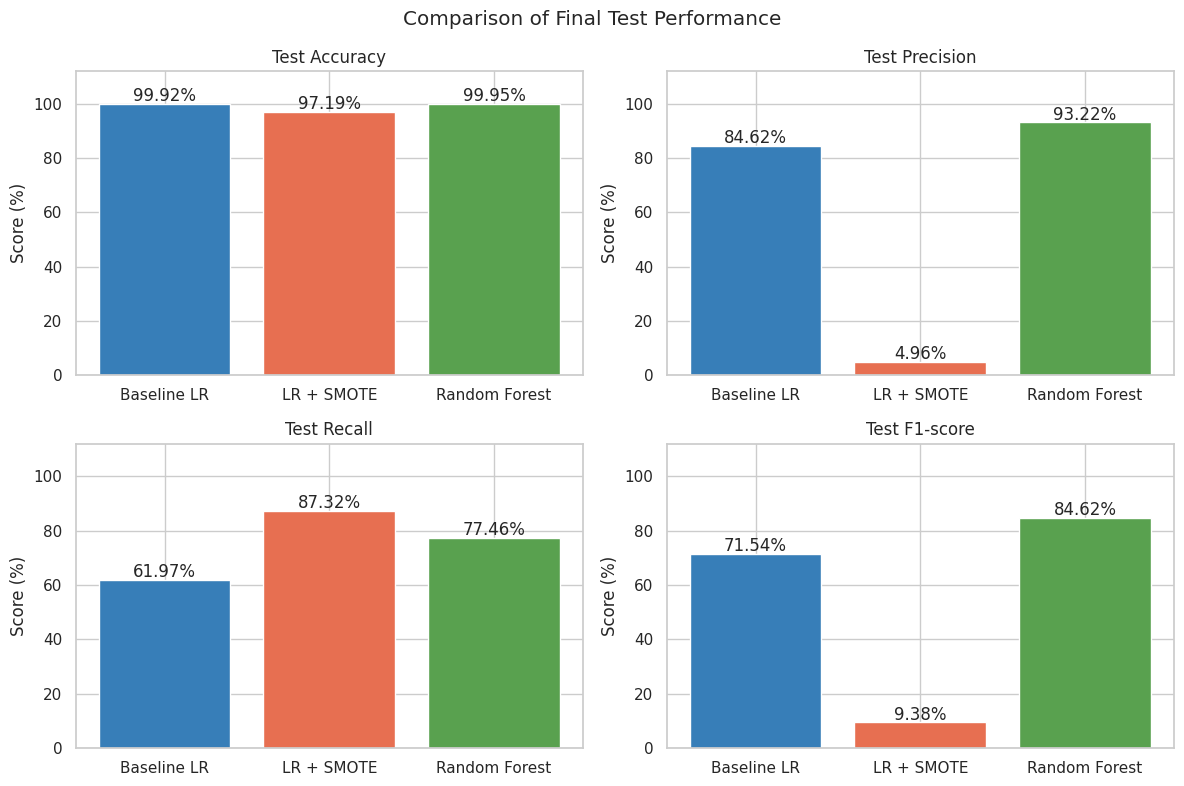

In [34]:
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
short_names = ["Baseline LR", "LR + SMOTE", "Random Forest"]
colors = ["#377eb8", "#e76f51", "#59a14f"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, metric in zip(axes.flat, metrics):
    values = test_results[metric].to_numpy() * 100

    bars = ax.bar(short_names, values, color=colors)
    ax.set_title(f"Test {metric}")
    ax.set_ylabel("Score (%)")
    ax.set_ylim(0, 112)

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 1,
            f"{value:.2f}%",
            ha="center"
        )

fig.suptitle("Comparison of Final Test Performance")
plt.tight_layout()
plt.show()

**Result:** Random Forest gives the strongest precision–recall balance. SMOTE catches more fraud but its false alarms cause very low precision; high accuracy alone hides these differences.

### Step 5.3 — Interpret the results and trade-offs
**Best minority-class performance:** Random Forest has the highest fraud F1-score (84.62%) and precision (93.22%). SMOTE has the highest recall (87.32%). Thus, Random Forest gives the best balance here, while SMOTE detects the most fraud.

**Effect of resampling:** Compared with the baseline, SMOTE raises detected fraud from 44 to 62 and reduces missed fraud from 27 to 9. However, false alarms increase from 8 to 1,189, reducing F1 from 71.54% to 9.38%. Balancing the training data does not guarantee better precision or F1.

**Effect of ensembling:** Random Forest improves baseline precision (84.62% to 93.22%) and recall (61.97% to 77.46%), and reduces false alarms from 8 to 4.

**Trade-off:** Random Forest misses 7 more fraud cases than SMOTE but produces 1,185 fewer false alarms. The practical choice depends on the costs of missed fraud and unnecessary reviews; those costs were not measured here.

**Limitation:** These results come from one fixed stratified split. They do not establish performance on future transactions.

### Step 5.4 — Explain metric calculations
For fraud as the positive class, TP means detected fraud, FN means missed fraud, FP means a false fraud alarm, and TN means correctly identified non-fraud.

| Metric | Formula | Random Forest test calculation |
|---|---|---|
| Accuracy | (TP + TN) / (TP + TN + FP + FN) | (55 + 42,484) / 42,559 = 99.9530% |
| Precision | TP / (TP + FP) | 55 / (55 + 4) = 93.2203% |
| Recall | TP / (TP + FN) | 55 / (55 + 16) = 77.4648% |
| F1-score | 2TP / (2TP + FP + FN) | 110 / (110 + 4 + 16) = 84.6154% |

### Step 5.5 — Conclusion
Random Forest achieved the best test F1-score in this experiment. SMOTE increased recall but caused many false alarms. Evaluating fraud detection therefore requires precision, recall, F1, and confusion matrices alongside accuracy.

### Dataset reference
Machine Learning Group, Université Libre de Bruxelles. *Credit Card Fraud Detection*. Kaggle. Dataset identifier: `mlg-ulb/creditcardfraud`.
